In [1]:
!pip install pandas numpy matplotlib seaborn wordcloud Sastrawi openpyxl emoji datasets -q

print("Semua library berhasil disiapkan!")

Semua library berhasil disiapkan!


In [2]:
import os
import re
import string
import emoji
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from wordcloud import WordCloud
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from collections import Counter
from IPython.display import display

print("Library berhasil di-import!")

Library berhasil di-import!


In [3]:
folders = [
    "data/raw",
    "data/processed",
    "output",
    "laporan"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Folder proyek berhasil dibuat!")

Folder proyek berhasil dibuat!


In [4]:
import urllib.request

url = "https://raw.githubusercontent.com/cahkanor/id-cyberbullying-instagram/master/id-cyberbullying-instagram.tsv"

file_path = "data/raw/dataset_github.tsv"

urllib.request.urlretrieve(url, file_path)

print("Dataset berhasil diunduh!")

Dataset berhasil diunduh!


In [6]:
df_github = pd.read_csv(
    "data/raw/dataset_github.tsv",
    sep="\t",
    encoding="latin-1"
)

print("Jumlah baris:", len(df_github))
print("Nama kolom:", df_github.columns.tolist())

display(df_github.head(10))

Jumlah baris: 300
Nama kolom: ['no', 'text', 'label']


,no,text,label
0,1,"Klo fadli zon goblok, boleeeh?",CB
1,2,"@detikcom Jangan nyinyirin pak fadli zon, dia ...",CB
2,3,@ahmadwaluy @bravo1282 @fadlizon Kritik siapa ...,CB
3,4,"@fadlizon @jokowi Hati penuh dendam, pikiran...",CB
4,5,@fadlizon @jokowi Kerja anda apa zon bisanya c...,CB
5,6,@fadlizon Fadli zon wakil rakyat bento otaknya...,CB
6,7,@Yayan_Anjasmara @fadlizon @jokowi Klau tong k...,CB
7,8,@fadlizon Koq gak pak fadli zon yg maju?? Kan ...,CB
8,9,@fadlizon @jokowi Memory terisisi aplikasi kri...,CB
9,10,@MataNajwa @fadlizon @TRANS7 Fadli Zon bukan m...,CB


In [7]:
print("INFORMASI DATASET")
print("=" * 40)

print("Jumlah baris:", df_github.shape[0])
print("Jumlah kolom:", df_github.shape[1])

print("\nTipe data:")
print(df_github.dtypes)

print("\nData kosong:")
print(df_github.isnull().sum())

print("\nData duplikat:")
print(df_github.duplicated().sum())

print("\nDistribusi label:")
print(df_github["label"].value_counts())

INFORMASI DATASET
Jumlah baris: 300
Jumlah kolom: 3

Tipe data:
no        int64
text     object
label    object
dtype: object

Data kosong:
no       0
text     0
label    0
dtype: int64

Data duplikat:
0

Distribusi label:
label
CB        150
Non_CB    150
Name: count, dtype: int64


In [8]:
df = df_github[["text", "label"]].copy()

df.columns = ["komentar", "label"]

# Menghapus data kosong
df = df.dropna(subset=["komentar", "label"])

# Mengubah teks menjadi string
df["komentar"] = df["komentar"].astype(str)

# Menghapus komentar kosong
df = df[df["komentar"].str.strip() != ""]

# Menghapus duplikasi berdasarkan komentar dan label
df = df.drop_duplicates(
    subset=["komentar", "label"]
).reset_index(drop=True)

# Menyeragamkan label
df["label"] = df["label"].str.strip()

print("Jumlah data setelah pembersihan:", len(df))

display(df.head())

Jumlah data setelah pembersihan: 299


,komentar,label
0,"Klo fadli zon goblok, boleeeh?",CB
1,"@detikcom Jangan nyinyirin pak fadli zon, dia ...",CB
2,@ahmadwaluy @bravo1282 @fadlizon Kritik siapa ...,CB
3,"@fadlizon @jokowi Hati penuh dendam, pikiran...",CB
4,@fadlizon @jokowi Kerja anda apa zon bisanya c...,CB


In [9]:
label_mapping = {
    "Non_CB": "aman",
    "CB": "toksik"
}

df["label"] = df["label"].replace(label_mapping)

print(df["label"].value_counts())

label
toksik    150
aman      149
Name: count, dtype: int64


In [10]:
slang_dict = {
    "yg": "yang",
    "gak": "tidak",
    "ga": "tidak",
    "nggak": "tidak",
    "ngga": "tidak",
    "enggak": "tidak",
    "tdk": "tidak",
    "bgt": "banget",
    "banget": "banget",
    "aja": "saja",
    "jd": "jadi",
    "dgn": "dengan",
    "utk": "untuk",
    "krn": "karena",
    "karna": "karena",
    "gw": "saya",
    "gue": "saya",
    "gua": "saya",
    "lu": "kamu",
    "lo": "kamu",
    "km": "kamu",
    "kmu": "kamu",
    "udh": "sudah",
    "udah": "sudah",
    "blm": "belum",
    "bkn": "bukan",
    "emg": "memang",
    "sm": "sama",
    "dr": "dari",
    "dpt": "dapat",
    "org": "orang",
    "kalo": "kalau",
    "kl": "kalau",
    "tp": "tetapi",
    "tpi": "tetapi",
    "trs": "terus",
    "mantul": "mantap",
    "wkwk": "",
    "wkwkwk": "",
    "lol": ""
}

def normalisasi_slang(teks):
    kata = teks.split()

    hasil = [
        slang_dict.get(k, k)
        for k in kata
    ]

    return " ".join(hasil)

print(normalisasi_slang("lu gak tau yg gw maksud"))

kamu tidak tau yang saya maksud


In [11]:
# Membuat stemmer Sastrawi
factory = StemmerFactory()
stemmer = factory.create_stemmer()

# Stopword bahasa Indonesia
stopwords = {
    "yang", "dan", "di", "ke", "dari",
    "ini", "itu", "atau", "untuk", "pada",
    "dengan", "adalah", "akan", "dalam",
    "juga", "karena", "saya", "kamu",
    "ia", "dia", "mereka", "kami", "kita",
    "ada", "tidak", "bukan", "sudah",
    "belum", "saja", "sangat", "lebih",
    "agar", "oleh", "sebagai", "dapat"
}

def cleaning_text(teks):

    teks = str(teks)

    # Case folding
    teks = teks.lower()

    # Menghapus URL
    teks = re.sub(r"http\S+|www\.\S+", "", teks)

    # Menghapus mention dan hashtag
    teks = re.sub(r"@\w+|#\w+", "", teks)

    # Menghapus emoji
    teks = emoji.replace_emoji(teks, replace="")

    # Menghapus angka
    teks = re.sub(r"\d+", "", teks)

    # Menghapus tanda baca dan simbol
    teks = re.sub(r"[^a-zA-Z\s]", " ", teks)

    # Menghapus spasi berlebihan
    teks = re.sub(r"\s+", " ", teks).strip()

    return teks


def preprocessing(teks):

    # Cleaning
    teks = cleaning_text(teks)

    # Normalisasi slang
    teks = normalisasi_slang(teks)

    # Tokenisasi sederhana
    tokens = teks.split()

    # Stopword removal
    tokens = [
        kata for kata in tokens
        if kata not in stopwords
    ]

    # Stemming
    tokens = [
        stemmer.stem(kata)
        for kata in tokens
    ]

    return " ".join(tokens)


print("Fungsi preprocessing berhasil dibuat!")

Fungsi preprocessing berhasil dibuat!


In [12]:
# Teks yang sudah dibersihkan
df["komentar_clean"] = df["komentar"].apply(
    cleaning_text
)

# Teks yang sudah dinormalisasi,
# stopword removal, dan stemming
df["komentar_preprocessed"] = df["komentar"].apply(
    preprocessing
)

display(
    df[[
        "komentar",
        "komentar_clean",
        "komentar_preprocessed",
        "label"
    ]].head(15)
)

,komentar,komentar_clean,komentar_preprocessed,label
0,"Klo fadli zon goblok, boleeeh?",klo fadli zon goblok boleeeh,klo fadli zon goblok boleeeh,toksik
1,"@detikcom Jangan nyinyirin pak fadli zon, dia ...",jangan nyinyirin pak fadli zon dia gitu punya ...,jangan nyinyirin pak fadli zon gitu punya pres...,toksik
2,@ahmadwaluy @bravo1282 @fadlizon Kritik siapa ...,kritik siapa bisa di penjara fadli zon kritik ...,kritik siapa bisa penjara fadli zon kritik pre...,toksik
3,"@fadlizon @jokowi Hati penuh dendam, pikiran...",hati penuh dendam pikiran selalu negatif mata ...,hati penuh dendam pikir selalu negatif mata ha...,toksik
4,@fadlizon @jokowi Kerja anda apa zon bisanya c...,kerja anda apa zon bisanya cuma nyinyi r aja s...,kerja anda apa zon bisa cuma nyinyi r moga mas...,toksik
5,@fadlizon Fadli zon wakil rakyat bento otaknya...,fadli zon wakil rakyat bento otaknya udah rusak,fadli zon wakil rakyat bento otak rusak,toksik
6,@Yayan_Anjasmara @fadlizon @jokowi Klau tong k...,klau tong kosong kan gtu asal bunyi,klau tong kosong kan gtu asal bunyi,toksik
7,@fadlizon Koq gak pak fadli zon yg maju?? Kan ...,koq gak pak fadli zon yg maju kan bapak hebat ...,koq pak fadli zon maju kan bapak hebat soal kr...,toksik
8,@fadlizon @jokowi Memory terisisi aplikasi kri...,memory terisisi aplikasi kritikan atau cemooha...,memory isis aplikasi kritik cemooh nyinyirin,toksik
9,@MataNajwa @fadlizon @TRANS7 Fadli Zon bukan m...,fadli zon bukan mengkritik tapi mulut rombenga...,fadli zon kritik tapi mulut rombeng alias nyab...,toksik


In [13]:
df.to_csv(
    "data/processed/dataset_preprocessed.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Dataset preprocessing berhasil disimpan!")

Dataset preprocessing berhasil disimpan!


In [14]:
print("=" * 50)
print("HASIL EXPLORATORY DATA ANALYSIS")
print("=" * 50)

print("Total komentar:", len(df))

print("\nJumlah komentar kosong:")
print(df["komentar"].isna().sum())

print("\nJumlah data duplikat:")
print(df.duplicated(subset=["komentar"]).sum())

print("\nDistribusi label:")
print(df["label"].value_counts())

print("\nPersentase label:")
print(
    df["label"].value_counts(normalize=True) * 100
)

HASIL EXPLORATORY DATA ANALYSIS
Total komentar: 299

Jumlah komentar kosong:
0

Jumlah data duplikat:
0

Distribusi label:
label
toksik    150
aman      149
Name: count, dtype: int64

Persentase label:
label
toksik    50.167224
aman      49.832776
Name: proportion, dtype: float64


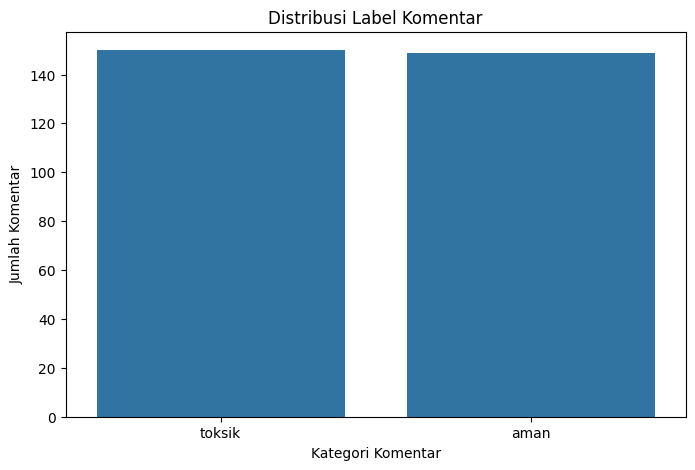

In [15]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="label"
)

plt.title("Distribusi Label Komentar")
plt.xlabel("Kategori Komentar")
plt.ylabel("Jumlah Komentar")

plt.savefig(
    "output/distribusi_label.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [16]:
df["panjang_teks"] = df["komentar_clean"].apply(
    lambda x: len(x.split())
)

print(df["panjang_teks"].describe())

count    299.000000
mean      17.622074
std       10.216498
min        2.000000
25%        9.500000
50%       16.000000
75%       23.000000
max       47.000000
Name: panjang_teks, dtype: float64


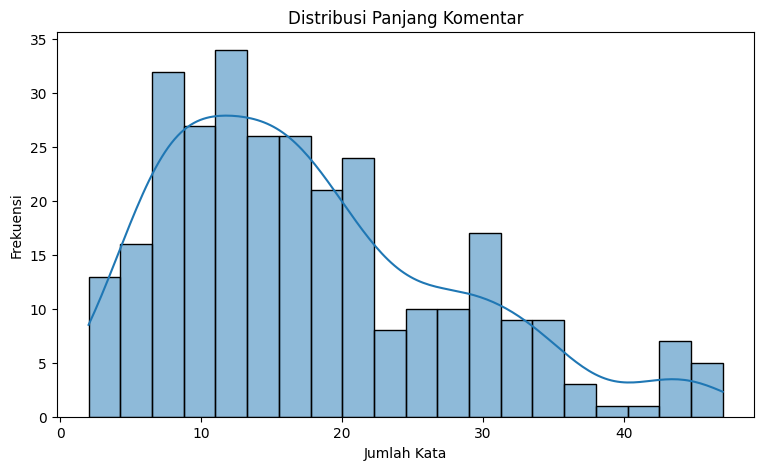

In [17]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="panjang_teks",
    bins=20,
    kde=True
)

plt.title("Distribusi Panjang Komentar")
plt.xlabel("Jumlah Kata")
plt.ylabel("Frekuensi")

plt.savefig(
    "output/distribusi_panjang_teks.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [18]:
semua_kata = " ".join(
    df["komentar_preprocessed"]
).split()

frekuensi_kata = Counter(semua_kata)

top_20 = frekuensi_kata.most_common(20)

df_frekuensi = pd.DataFrame(
    top_20,
    columns=["Kata", "Frekuensi"]
)

display(df_frekuensi)

,Kata,Frekuensi
0,zon,130
1,fadli,120
2,pak,62
3,jadi,41
4,narkoba,38
5,rakyat,37
6,orang,37
7,bisa,36
8,kan,35
9,kalau,34


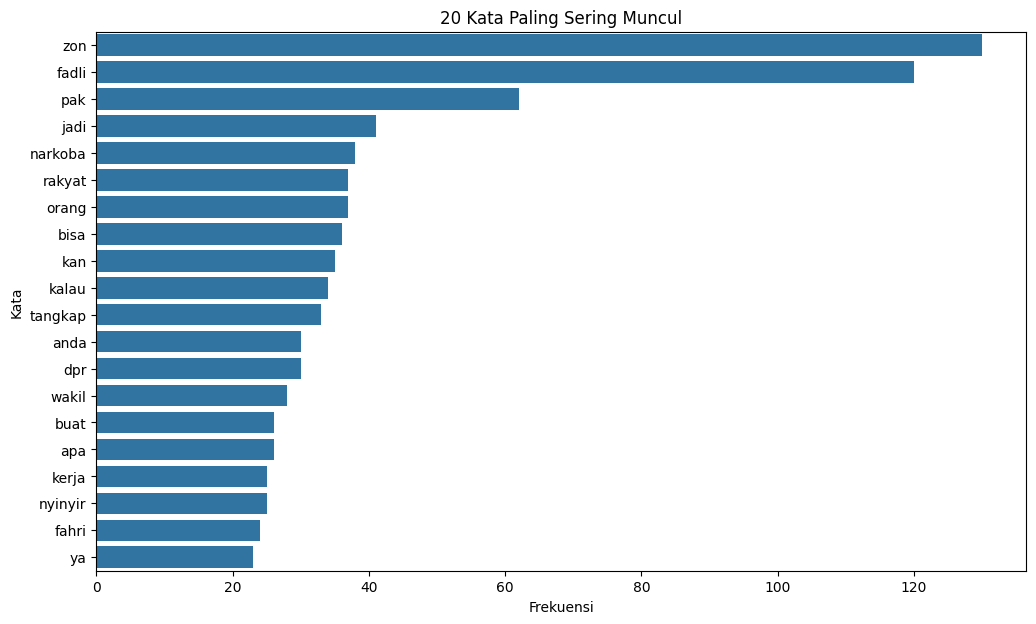

In [19]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=df_frekuensi,
    x="Frekuensi",
    y="Kata"
)

plt.title("20 Kata Paling Sering Muncul")
plt.xlabel("Frekuensi")
plt.ylabel("Kata")

plt.savefig(
    "output/frekuensi_kata.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

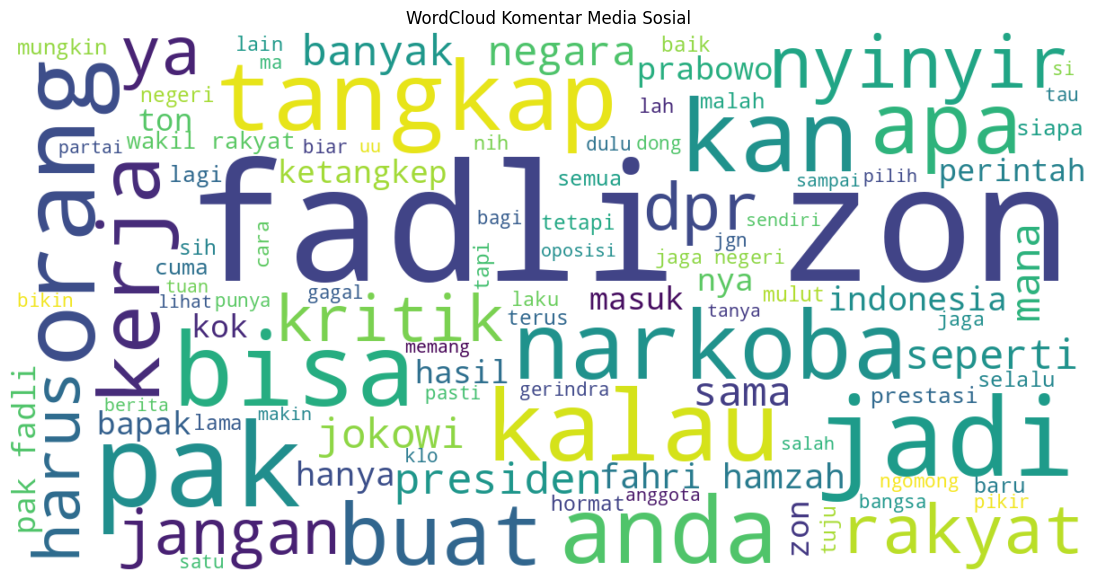

In [20]:
teks_gabungan = " ".join(
    df["komentar_preprocessed"]
)

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    max_words=100
).generate(teks_gabungan)

plt.figure(figsize=(14, 7))

plt.imshow(
    wordcloud,
    interpolation="bilinear"
)

plt.axis("off")
plt.title("WordCloud Komentar Media Sosial")

plt.savefig(
    "output/wordcloud.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

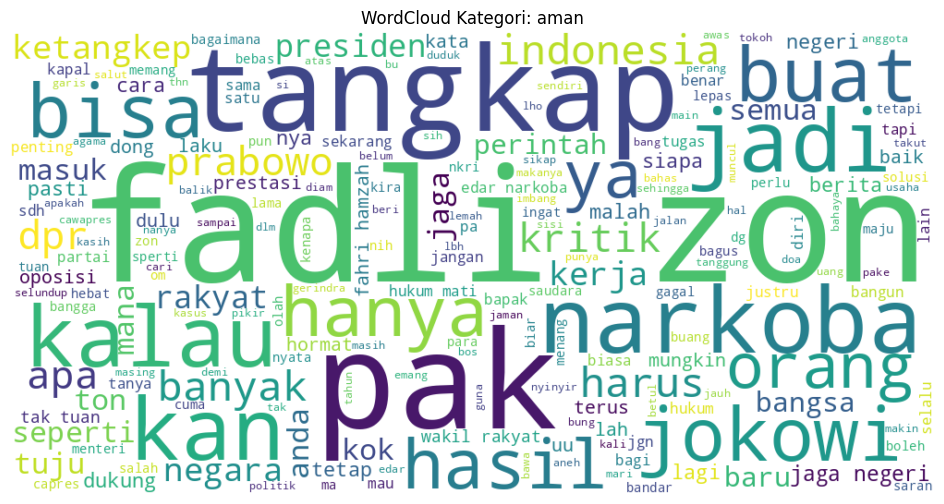

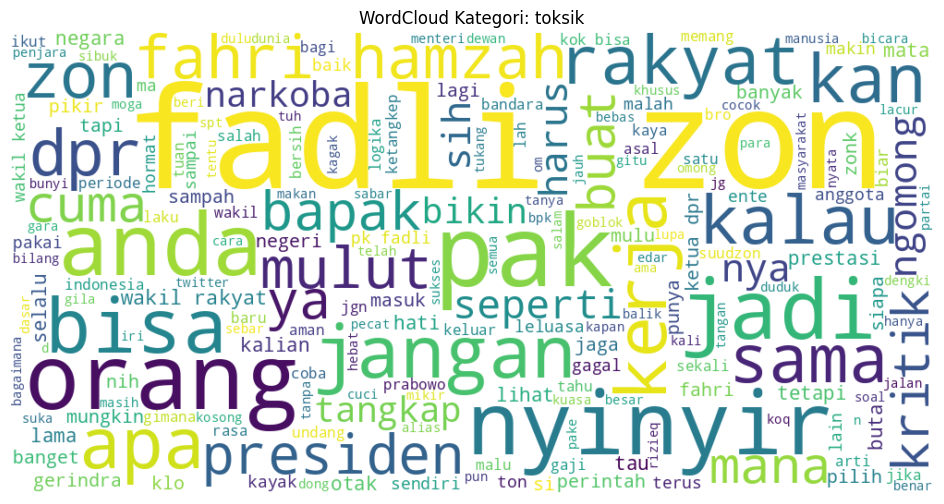

In [21]:
for kategori in ["aman", "toksik"]:

    teks = " ".join(
        df[df["label"] == kategori][
            "komentar_preprocessed"
        ]
    )

    wc = WordCloud(
        width=1000,
        height=500,
        background_color="white"
    ).generate(teks)

    plt.figure(figsize=(12, 6))
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title("WordCloud Kategori: " + kategori)

    plt.savefig(
        f"output/wordcloud_{kategori}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [22]:
df_final = df[[
    "komentar",
    "komentar_clean",
    "komentar_preprocessed",
    "label"
]].copy()

df_final.to_csv(
    "data/processed/dataset_clean.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Dataset final berhasil disimpan!")

display(df_final.head(10))

Dataset final berhasil disimpan!


,komentar,komentar_clean,komentar_preprocessed,label
0,"Klo fadli zon goblok, boleeeh?",klo fadli zon goblok boleeeh,klo fadli zon goblok boleeeh,toksik
1,"@detikcom Jangan nyinyirin pak fadli zon, dia ...",jangan nyinyirin pak fadli zon dia gitu punya ...,jangan nyinyirin pak fadli zon gitu punya pres...,toksik
2,@ahmadwaluy @bravo1282 @fadlizon Kritik siapa ...,kritik siapa bisa di penjara fadli zon kritik ...,kritik siapa bisa penjara fadli zon kritik pre...,toksik
3,"@fadlizon @jokowi Hati penuh dendam, pikiran...",hati penuh dendam pikiran selalu negatif mata ...,hati penuh dendam pikir selalu negatif mata ha...,toksik
4,@fadlizon @jokowi Kerja anda apa zon bisanya c...,kerja anda apa zon bisanya cuma nyinyi r aja s...,kerja anda apa zon bisa cuma nyinyi r moga mas...,toksik
5,@fadlizon Fadli zon wakil rakyat bento otaknya...,fadli zon wakil rakyat bento otaknya udah rusak,fadli zon wakil rakyat bento otak rusak,toksik
6,@Yayan_Anjasmara @fadlizon @jokowi Klau tong k...,klau tong kosong kan gtu asal bunyi,klau tong kosong kan gtu asal bunyi,toksik
7,@fadlizon Koq gak pak fadli zon yg maju?? Kan ...,koq gak pak fadli zon yg maju kan bapak hebat ...,koq pak fadli zon maju kan bapak hebat soal kr...,toksik
8,@fadlizon @jokowi Memory terisisi aplikasi kri...,memory terisisi aplikasi kritikan atau cemooha...,memory isis aplikasi kritik cemooh nyinyirin,toksik
9,@MataNajwa @fadlizon @TRANS7 Fadli Zon bukan m...,fadli zon bukan mengkritik tapi mulut rombenga...,fadli zon kritik tapi mulut rombeng alias nyab...,toksik


In [23]:
import shutil

shutil.make_archive(
    "Anggota_2_M_Hafizh",
    "zip",
    "."
)

from google.colab import files

files.download("Anggota_2_M_Hafizh.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>